# Nes2Net: tái hiện paper (Kaggle · Colab · local)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trinhphamtrunghieu/nes2net-fake-voice-detection/blob/main/notebooks/nes2net.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/trinhphamtrunghieu/nes2net-fake-voice-detection/blob/main/notebooks/nes2net.ipynb)

**Paper:** *Nes2Net: A Lightweight Nested Architecture for Foundation Model Driven Speech Anti-spoofing*
(Liu, Truong, Das, Lee, Li, IEEE T-IFS 2025, [arXiv:2504.05657](https://arxiv.org/abs/2504.05657)).

Một notebook cho mọi nền tảng: notebook tự nhận Kaggle / Colab / local và chọn chỗ lưu (`/kaggle/working`,
Google Drive, `./work`). Code nằm trong package `nes2net/`; notebook chỉ chọn **preset** và gọi các hàm của nó.

| Preset | Chạy gì | Thời gian (T4) |
|---|---|---|
| `smoke` | tập con rất nhỏ của mọi phần, chỉ để kiểm tra pipeline | ~30 phút |
| `default` | **A** checkpoint chính thức trên tập con · **C** ablation · **C2** chọn layer SSL | ~3–4 giờ |
| `full_eval` | **A** trên toàn bộ LA19 / ITW / 2021 LA / 2021 DF · **C** · **C2** | ~6–8 giờ |
| `paper_train` | **B** train đúng công thức paper (lr 2.5e-7, bs 12, 100 epoch, RawBoost 4), resume qua nhiều phiên | ~80–100 giờ |

**Chuẩn bị:** GPU (Kaggle: T4, Internet **On**; Colab: *Runtime → Change runtime type → GPU*, Pro nên chọn A100/L4).
Trên Colab, ô Setup xin quyền mount Google Drive để lưu kết quả và trạng thái resume.
Dữ liệu tải từ Hugging Face Hub (`Bisher/ASVspoof_2019_LA`, `SpeechAntiSpoofingBenchmarks/*`).

In [ ]:
# ---------------- Setup: clone/cập nhật repo, cài thư viện ----------------
import os, subprocess, sys
REPO_URL = 'https://github.com/trinhphamtrunghieu/nes2net-fake-voice-detection.git'
REPO_REF = 'main'   # ghim một commit/tag (vd '154b3b4') cho các lần train dài để code không đổi giữa các phiên
IN_COLAB, IN_KAGGLE = 'google.colab' in sys.modules, os.path.isdir('/kaggle/working')
REPO_DIR = ('/content/nes2net-fake-voice-detection' if IN_COLAB else
            '/tmp/nes2net-fake-voice-detection' if IN_KAGGLE else os.path.abspath('nes2net-fake-voice-detection'))
if 'nes2net' in sys.modules:
    print('!! nes2net đã được import trong runtime này: Runtime → Restart session rồi chạy lại để nạp code mới')
if not os.path.isdir(REPO_DIR):
    subprocess.run(['git', 'clone', '-q', REPO_URL, REPO_DIR], check=True)
subprocess.run(['git', '-C', REPO_DIR, 'fetch', '-q', 'origin'], check=True)
subprocess.run(['git', '-C', REPO_DIR, 'checkout', '-q', REPO_REF], check=True)
if REPO_REF == 'main':
    subprocess.run(['git', '-C', REPO_DIR, 'pull', '-q', 'origin', 'main'], check=True)
print('code @', subprocess.run(['git', '-C', REPO_DIR, 'log', '-1', '--format=%h %s'], capture_output=True, text=True).stdout)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', os.path.join(REPO_DIR, 'requirements.txt')], check=True)
sys.path.insert(0, REPO_DIR)

In [ ]:
# ---------------- Config ----------------
PRESET = 'paper_train'   # 'smoke' | 'default' | 'full_eval' | 'paper_train'
OVERRIDES = {}       # ghi đè bất kỳ khoá nào, vd {'B': {'lr': 2e-6}, 'run': {'L': False}}
USE_DRIVE = True     # Colab: lưu WORK lên Google Drive

from nes2net import env as nenv, presets, run
from IPython.display import display
ENV = nenv.setup(use_drive=USE_DRIVE)
cfg = presets.get(PRESET, ENV.platform, OVERRIDES)
print(ENV); presets.show(cfg)

## 0. Kiểm tra nhanh: back-end khớp bit-for-bit với code gốc, số tham số ≈ 511k

In [ ]:
if cfg['run']['sanity']:
    display(run.sanity(ENV))

## A. Checkpoint chính thức → đánh giá
`load_official_checkpoint` chuyển key fairseq sang HF `Wav2Vec2Model` (không cần fairseq) và nạp **strict**.
Giao thức: cửa sổ 4 s đầu như code gốc; ITW chấm thêm cả câu. ASVspoof 2021: script chấm chính thức chỉ tính
trial `phase == eval` (con số của paper); Arena tính **toàn bộ** trial. Preset `full_eval` báo cả hai, kèm EER theo codec/vocoder.

In [ ]:
if cfg['run']['A']:
    RA = run.eval_official(cfg, ENV)
    display(run.results_table(RA))
if cfg['run']['A_full']:
    RAF = run.eval_official_full(cfg, ENV)       # chạy lại được: shard đã chấm sẽ bỏ qua
    display(run.results_table(RAF))
    for k, v in RAF.items():
        if 'phase_eval_breakdown_eer' in v:
            print(k, {a: round(e, 2) for a, e in v['phase_eval_breakdown_eer'].items()})

## B. Train end-to-end
XLS-R 300M fine-tune + Nes2Net-X `[8,8]`, SE 1, dilation 2, mean pooling, Adam (wd 1e-4), weighted CE `[0.1, 0.9]`,
RawBoost algo 4, cửa sổ 4 s đầu; lưu checkpoint khi val loss (có/không aug) giảm.

**Resume:** trạng thái ghi vào `WORK/runB/last_state.pth` mỗi `save_every_steps` bước và cuối mỗi epoch; mỗi phiên dừng
an toàn sau `time_budget_h`. Bị ngắt hoặc hết giờ → chạy lại notebook với cùng preset. Trên Kaggle, thêm output của
lần chạy trước làm input của kernel: `runB/` được copy về tự động. Khi đủ epoch: `OVERRIDES = {'run': {'B': False, 'B_eval': True}}`.

In [ ]:
if cfg['run']['B']:
    HIST = run.train(cfg, ENV)
if cfg['run']['B_eval']:
    display(run.eval_trained(cfg, ENV))

### Log của phần B
`WORK/runB/train.log` (dạng chữ), `metrics.jsonl` (JSON từng sự kiện), `tb/` (TensorBoard). Cứ `log_every` bước một
dòng gồm loss, lr, utt/s, % thời gian chờ DataLoader, GPU memory, ETA; cuối epoch: val loss và val EER.

In [ ]:
SHOW_TB = False
if cfg['run']['B'] or os.path.exists(os.path.join(ENV.work, cfg['B']['out'], 'metrics.jsonl')):
    run.plot_train_logs(os.path.join(ENV.work, cfg['B']['out']), show_tb=SHOW_TB)

## C. Ablation back-end trên đặc trưng XLS-R đóng băng
Đặc trưng XLS-R (pre-trained, không fine-tune) của cửa sổ 4 s được cache fp16 một lần; mỗi back-end train vài phút.
EER tuyệt đối cao hơn paper, chỉ so sánh **tương đối** giữa các biến thể (mean ± std qua seed).
Nhóm A0–A5: baseline, tỉ lệ lồng, SE, pooling, dilation/kernel, bỏ kết nối tích luỹ (xem `docs/ablation_and_gaps.md`).

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

extract asv19_test_n4000:   0%|          | 0/125 [00:00<?, ?it/s]

extract hfbench_InTheWild_n4000:   0%|          | 0/125 [00:00<?, ?it/s]

{'backend': 'mean_linear', 'seed': 0, 'dev_eer': 5.01, 'params_k': 2.05, 'mmacs': 0.002, 'train_min': 6.162, 'asv19_test_n4000_eer': 7.774, 'hfbench_InTheWild_n4000_eer': 26.973, 'group': 'A0_baselines', 'cfg': '{"backend": "mean_linear"}'}
{'backend': 'mean_linear', 'seed': 1, 'dev_eer': 4.104, 'params_k': 2.05, 'mmacs': 0.002, 'train_min': 6.197, 'asv19_test_n4000_eer': 7.533, 'hfbench_InTheWild_n4000_eer': 23.974, 'group': 'A0_baselines', 'cfg': '{"backend": "mean_linear"}'}
{'backend': 'mean_linear', 'seed': 2, 'dev_eer': 5.547, 'params_k': 2.05, 'mmacs': 0.002, 'train_min': 6.285, 'asv19_test_n4000_eer': 9.072, 'hfbench_InTheWild_n4000_eer': 24.827, 'group': 'A0_baselines', 'cfg': '{"backend": "mean_linear"}'}
{'backend': 'dr_res2net', 'D': 128, 'scale': 4, 'seed': 0, 'dev_eer': 0.453, 'params_k': 178.994, 'mmacs': 34.789, 'train_min': 6.217, 'asv19_test_n4000_eer': 1.82, 'hfbench_InTheWild_n4000_eer': 23.247, 'group': 'A0_baselines', 'cfg': '{"D": 128, "backend": "dr_res2net", "s

dev_eer  \
                                                                         mean   
group              cfg                                                          
A0_baselines       {"D": 128, "backend": "dr_res2net", "scale": 4}       0.45   
                   {"backend": "mean_linear"}                            4.89   
                   {"backend": "nes2net"}                                0.78   
                   {"backend": "nes2net_x"}                              0.91   
A1_nest_ratio      {"Nes_ratio": [16, 4], "backend": "nes2net_x"}        1.51   
                   {"Nes_ratio": [16, 8], "backend": "nes2net_x"}        1.34   
                   {"Nes_ratio": [32, 4], "backend": "nes2net_x"}        1.83   
                   {"Nes_ratio": [4, 4], "backend": "nes2net_x"}         0.46   
                   {"Nes_ratio": [4, 8], "backend": "nes2net_x"}         0.51   
                   {"Nes_ratio": [8, 16], "backend": "nes2net_x"}        0.91   
                   {"Nes_ratio": [8, 4], "backend": "nes2net_x"}         1.06   
                   {"Nes_ratio": [8, 8], "backend": "nes2net_x"}         1.04   
A2_se_ratio        {"SE_ratio": [16], "backend": "nes2net_x"}            0.77   
                   {"SE_ratio": [1], "backend": "nes2net_x"}             0.58   
                   {"SE_ratio": [4], "backend": "nes2net_x"}             1.24   
                   {"SE_ratio": [8], "backend": "nes2net_x"}             0.59   
                   {"backend": "nes2net_x", "use_se": false}             0.78   
A3_pooling         {"backend": "nes2net_x", "pool_func": "ASTP"}         1.68   
                   {"backend": "nes2net_x", "pool_func": "mean"}         0.91   
A4_dilation_kernel {"backend": "nes2net_x", "dilation": 1, "kernel...    1.24   
                   {"backend": "nes2net_x", "dilation": 1}               1.01   
                   {"backend": "nes2net_x", "dilation": 2}               0.79   
                   {"backend": "nes2net_x", "dilation": 3}               1.01   
A5_connections     {"backend": "nes2net_x", "inner_hier": false, "...    0.45   
                   {"backend": "nes2net_x", "inner_hier": false}         1.39   
                   {"backend": "nes2net_x", "outer_hier": false}         0.46   

                                                                             \
                                                                        std   
group              cfg                                                        
A0_baselines       {"D": 128, "backend": "dr_res2net", "scale": 4}     0.00   
                   {"backend": "mean_linear"}                          0.73   
                   {"backend": "nes2net"}                              0.21   
                   {"backend": "nes2net_x"}                            0.45   
A1_nest_ratio      {"Nes_ratio": [16, 4], "backend": "nes2net_x"}      0.29   
                   {"Nes_ratio": [16, 8], "backend": "nes2net_x"}      0.88   
                   {"Nes_ratio": [32, 4], "backend": "nes2net_x"}      0.45   
                   {"Nes_ratio": [4, 4], "backend": "nes2net_x"}       0.02   
                   {"Nes_ratio": [4, 8], "backend": "nes2net_x"}       0.06   
                   {"Nes_ratio": [8, 16], "backend": "nes2net_x"}      0.00   
                   {"Nes_ratio": [8, 4], "backend": "nes2net_x"}       0.26   
                   {"Nes_ratio": [8, 8], "backend": "nes2net_x"}       0.28   
A2_se_ratio        {"SE_ratio": [16], "backend": "nes2net_x"}          0.28   
                   {"SE_ratio": [1], "backend": "nes2net_x"}           0.24   
                   {"SE_ratio": [4], "backend": "nes2net_x"}           0.60   
                   {"SE_ratio": [8], "backend": "nes2net_x"}           0.21   
                   {"backend": "nes2net_x", "use_se": false}           0.50   
A3_pooling         {"backend": "nes2net_x", "pool_func": "ASTP"}       0.54   
                   {"backend": "nes2net_x", "pool_func": "mea

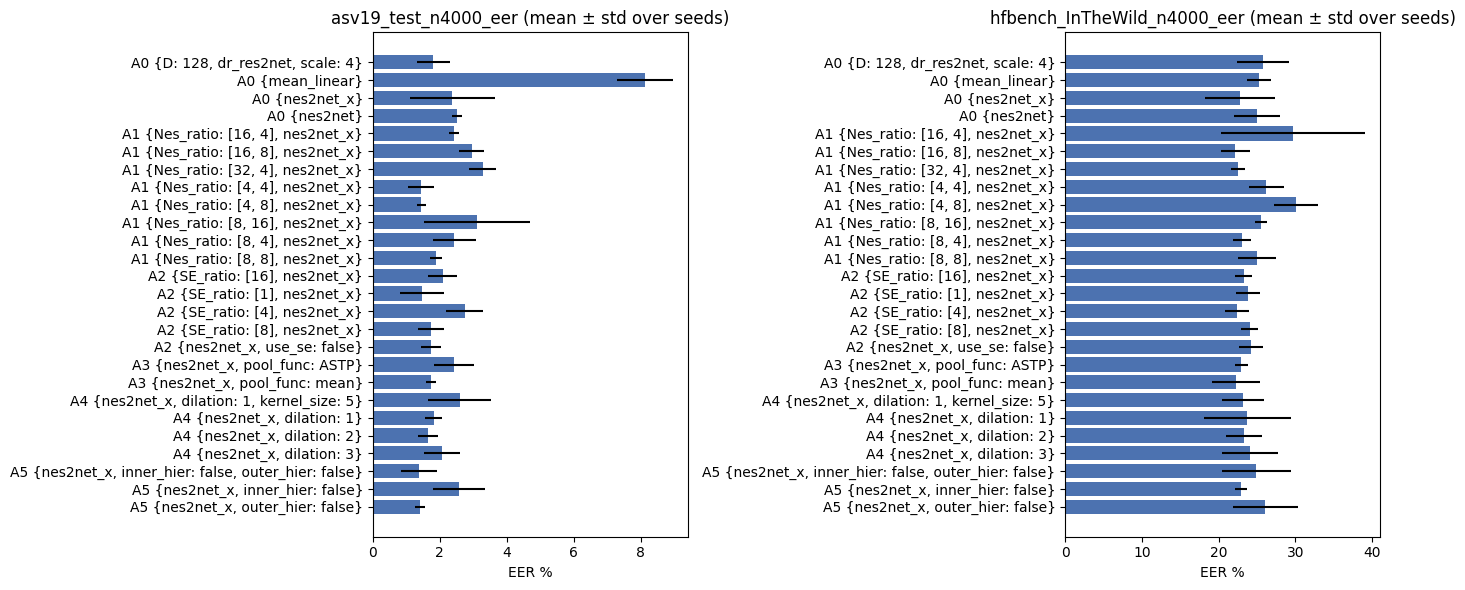

In [ ]:
if cfg['run']['C']:
    from nes2net.ablation import summarize
    DFC = run.ablation(cfg, ENV)
    display(summarize(DFC))
    run.plot_ablation(DFC, ENV)

### C2. Chọn layer SSL (research gap G1): từng layer so với tổng có trọng số học được

In [ ]:
if cfg['run']['L']:
    DFL = run.layer_study(cfg, ENV)
    display(DFL.groupby('layers')[['dev_eer', 'itw_eer']].agg(['mean', 'std']).round(2))

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


extract asv19_train_n3000:   0%|          | 0/94 [00:00<?, ?it/s]

extract asv19_validation_n1000:   0%|          | 0/32 [00:00<?, ?it/s]

extract hfbench_InTheWild_n2000:   0%|          | 0/63 [00:00<?, ?it/s]

22:34:35 INFO  nes2net.run | layer L8 seed 0: ITW EER 22.05%
22:37:22 INFO  nes2net.run | layer L8 seed 1: ITW EER 25.84%
22:40:11 INFO  nes2net.run | layer L8 seed 2: ITW EER 28.54%
22:43:15 INFO  nes2net.run | layer L12 seed 0: ITW EER 26.10%
22:46:01 INFO  nes2net.run | layer L12 seed 1: ITW EER 29.31%
22:48:34 INFO  nes2net.run | layer L12 seed 2: ITW EER 26.35%
22:51:38 INFO  nes2net.run | layer L18 seed 0: ITW EER 24.89%
22:54:30 INFO  nes2net.run | layer L18 seed 1: ITW EER 28.25%
22:57:20 INFO  nes2net.run | layer L18 seed 2: ITW EER 28.14%
23:00:22 INFO  nes2net.run | layer L24 seed 0: ITW EER 26.60%
23:03:13 INFO  nes2net.run | layer L24 seed 1: ITW EER 21.35%
23:05:51 INFO  nes2net.run | layer L24 seed 2: ITW EER 21.50%
23:21:18 INFO  nes2net.run | layer mix[8, 12, 18, 24] seed 0: ITW EER 23.40%
23:37:01 INFO  nes2net.run | layer mix[8, 12, 18, 24] seed 1: ITW EER 25.84%
23:52:56 INFO  nes2net.run | layer mix[8, 12, 18, 24] seed 2: ITW EER 25.95%


dev_eer       itw_eer      
                      mean   std    mean   std
layers                                        
L12                   0.06  0.06   27.25  1.78
L18                   0.36  0.49   27.09  1.91
L24                   1.37  1.38   23.15  2.99
L8                    0.00  0.00   25.48  3.26
mix[8, 12, 18, 24]    0.02  0.03   25.06  1.44

## Kết quả trong `WORK`
`partA_results.json` · `partA_full_results.json` + `A_full/` · `runB/` · `partB_results.json` ·
`partC_ablation.csv/.png` · `partC_layers.csv`. Dòng lệnh tương đương: `python -m nes2net.run --preset <tên>`.